# Student Habits — Regression & Classification (Simple Version)

A straightforward, easy-to-follow notebook — no pipelines or heavy
abstraction, just plain scikit-learn calls so each step is easy to read.

**Regression** (predicting the exact `exam_score`):
- Linear Regression
- Polynomial Regression
- Ridge & Lasso (regularized regression)

**Classification** (predicting `Pass`/`Fail`):
- Logistic Regression
- K-Nearest Neighbors (KNN)

> **Colab note:** Upload `student_habits_performance.csv` first. A synthetic
> fallback keeps the notebook runnable without it.


In [1]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    mean_squared_error, r2_score,
    accuracy_score, confusion_matrix, classification_report,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 5)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


## 1. Load Data

In [2]:
DATA_PATH = "student_habits_performance.csv"

def generate_synthetic_dataset(n=1000):
    study_hours = np.clip(np.random.normal(4.0, 1.8, n), 0, 12)
    sleep_hours = np.clip(np.random.normal(6.8, 1.2, n), 3, 10)
    attendance = np.clip(np.random.normal(85, 10, n), 40, 100)
    social_media = np.clip(np.random.normal(2.5, 1.3, n), 0, 8)
    exam_score = np.clip(
        study_hours * 6.5 + sleep_hours * 2.0 + attendance * 0.25
        - social_media * 3.0 + np.random.normal(0, 8, n),
        0, 100
    ).round(1)
    return pd.DataFrame({
        "study_hours_per_day": study_hours.round(1),
        "sleep_hours": sleep_hours.round(1),
        "attendance_percentage": attendance.round(1),
        "social_media_hours": social_media.round(1),
        "exam_score": exam_score,
    })

if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)
    print(f"Loaded real dataset: {df.shape}")
else:
    print("CSV not found — using synthetic fallback.")
    df = generate_synthetic_dataset(1000)

df = df.dropna(subset=["exam_score", "study_hours_per_day"]).drop_duplicates()
df.head()


Loaded real dataset: (1000, 9)


,student_id,study_hours_per_day,social_media_hours,netflix_hours,attendance_percentage,sleep_hours,mental_health_rating,exercise_frequency,exam_score
0,S0001,3.96,2.72,1.05,94.5,7.00,5,7,72.7
1,S0002,1.94,1.85,0.83,88.9,7.77,5,2,57.4
2,S0003,4.63,2.26,1.93,100.0,7.03,5,1,79.9
3,S0004,4.91,3.62,1.75,66.5,9.39,7,0,76.4
4,S0005,0.57,2.80,0.10,79.3,8.42,6,6,60.9


## 2. Regression — Predicting `exam_score`

Start simple: use just `study_hours_per_day` to predict `exam_score`, so the
line/curve can be plotted directly and understood at a glance.


In [3]:
X = df[["study_hours_per_day"]].values   # single feature, kept 2D as sklearn expects
y = df["exam_score"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train size:", len(X_train), "| Test size:", len(X_test))


Train size: 800 | Test size: 200


### 2.1 Linear Regression

Coefficient: 4.90  Intercept: 50.87
R2 score: 0.286
RMSE: 11.00


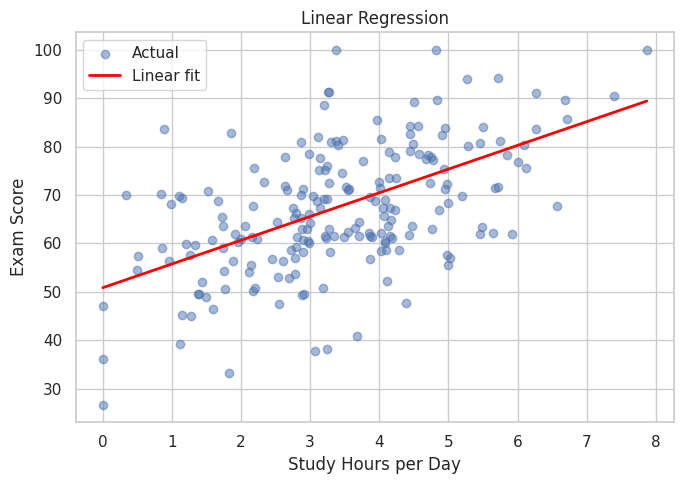

In [4]:
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_pred_lin = lin_reg.predict(X_test)

print(f"Coefficient: {lin_reg.coef_[0]:.2f}  Intercept: {lin_reg.intercept_:.2f}")
print(f"R2 score: {r2_score(y_test, y_pred_lin):.3f}")
print(f"RMSE: {mean_squared_error(y_test, y_pred_lin) ** 0.5:.2f}")

fig, ax = plt.subplots()
ax.scatter(X_test, y_test, alpha=0.5, label="Actual")
order = np.argsort(X_test[:, 0])
ax.plot(X_test[order], y_pred_lin[order], color="red", linewidth=2, label="Linear fit")
ax.set_xlabel("Study Hours per Day"); ax.set_ylabel("Exam Score")
ax.set_title("Linear Regression")
ax.legend()
plt.tight_layout()
plt.show()


### 2.2 Polynomial Regression

R2 score: 0.285
RMSE: 11.01


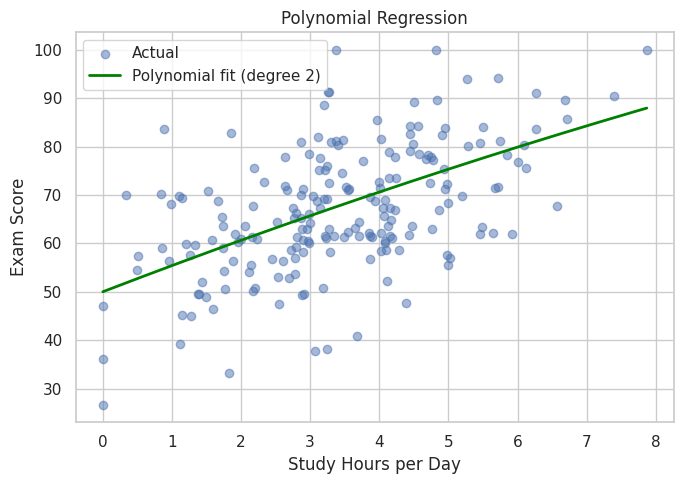

In [5]:
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

poly_reg = LinearRegression()
poly_reg.fit(X_train_poly, y_train)
y_pred_poly = poly_reg.predict(X_test_poly)

print(f"R2 score: {r2_score(y_test, y_pred_poly):.3f}")
print(f"RMSE: {mean_squared_error(y_test, y_pred_poly) ** 0.5:.2f}")

fig, ax = plt.subplots()
ax.scatter(X_test, y_test, alpha=0.5, label="Actual")
x_line = np.linspace(X_test.min(), X_test.max(), 200).reshape(-1, 1)
y_line = poly_reg.predict(poly.transform(x_line))
ax.plot(x_line, y_line, color="green", linewidth=2, label="Polynomial fit (degree 2)")
ax.set_xlabel("Study Hours per Day"); ax.set_ylabel("Exam Score")
ax.set_title("Polynomial Regression")
ax.legend()
plt.tight_layout()
plt.show()


### 2.3 Ridge & Lasso (Regularized Regression)

Same idea as Linear Regression, but with a penalty that shrinks the
coefficients — useful when using several features so the model doesn't
over-rely on any single one. Here we bring in a few more features to make
the regularization effect visible.


In [6]:
features = ["study_hours_per_day", "sleep_hours", "attendance_percentage", "social_media_hours"]
X_multi = df[features].values
y_multi = df["exam_score"].values

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y_multi, test_size=0.2, random_state=RANDOM_STATE
)

# Scale features first — regularization penalizes coefficient size,
# so features need to be on the same scale for that to be fair.
scaler = StandardScaler()
X_train_m_scaled = scaler.fit_transform(X_train_m)
X_test_m_scaled = scaler.transform(X_test_m)

ridge = Ridge(alpha=1.0)
ridge.fit(X_train_m_scaled, y_train_m)
y_pred_ridge = ridge.predict(X_test_m_scaled)

lasso = Lasso(alpha=0.1)
lasso.fit(X_train_m_scaled, y_train_m)
y_pred_lasso = lasso.predict(X_test_m_scaled)

print("Ridge  -> R2:", round(r2_score(y_test_m, y_pred_ridge), 3),
      " RMSE:", round(mean_squared_error(y_test_m, y_pred_ridge) ** 0.5, 2))
print("Lasso  -> R2:", round(r2_score(y_test_m, y_pred_lasso), 3),
      " RMSE:", round(mean_squared_error(y_test_m, y_pred_lasso) ** 0.5, 2))

coef_compare = pd.DataFrame({
    "feature": features,
    "ridge_coef": ridge.coef_.round(2),
    "lasso_coef": lasso.coef_.round(2),
})
coef_compare


Ridge  -> R2: 0.428  RMSE: 9.84
Lasso  -> R2: 0.426  RMSE: 9.86


,feature,ridge_coef,lasso_coef
0,study_hours_per_day,7.09,7.00
1,sleep_hours,1.70,1.60
2,attendance_percentage,2.75,2.66
3,social_media_hours,-2.76,-2.67


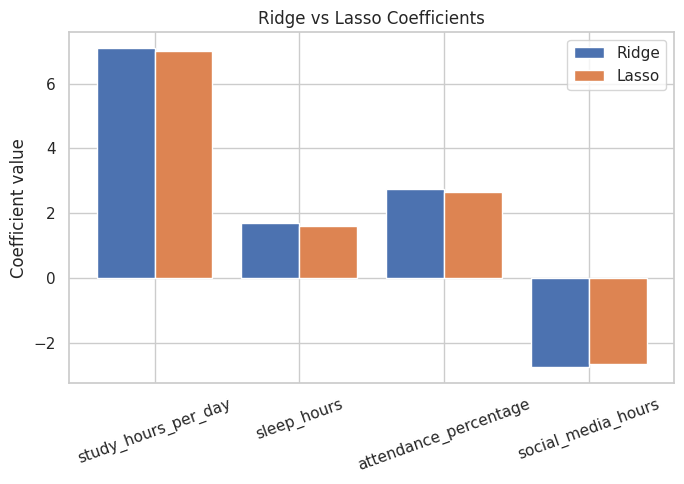

In [7]:
# Lasso can shrink coefficients all the way to zero (feature selection),
# Ridge only shrinks them smaller. Easy to see side by side:
fig, ax = plt.subplots()
x_pos = np.arange(len(features))
ax.bar(x_pos - 0.2, coef_compare["ridge_coef"], width=0.4, label="Ridge")
ax.bar(x_pos + 0.2, coef_compare["lasso_coef"], width=0.4, label="Lasso")
ax.set_xticks(x_pos)
ax.set_xticklabels(features, rotation=20)
ax.set_ylabel("Coefficient value")
ax.set_title("Ridge vs Lasso Coefficients")
ax.legend()
plt.tight_layout()
plt.show()


## 3. Classification — Predicting `Pass`/`Fail`

`exam_score >= 60` -> Pass (1), else Fail (0).


In [8]:
df["pass_fail"] = (df["exam_score"] >= 60).astype(int)

X_clf = df[features].values
y_clf = df["pass_fail"].values

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=RANDOM_STATE, stratify=y_clf
)

scaler_c = StandardScaler()
X_train_c_scaled = scaler_c.fit_transform(X_train_c)
X_test_c_scaled = scaler_c.transform(X_test_c)

print("Train size:", len(X_train_c), "| Test size:", len(X_test_c))


Train size: 800 | Test size: 200


### 3.1 Logistic Regression

Accuracy: 0.81
              precision    recall  f1-score   support

        Fail       0.70      0.49      0.58        53
        Pass       0.83      0.93      0.88       147

    accuracy                           0.81       200
   macro avg       0.77      0.71      0.73       200
weighted avg       0.80      0.81      0.80       200



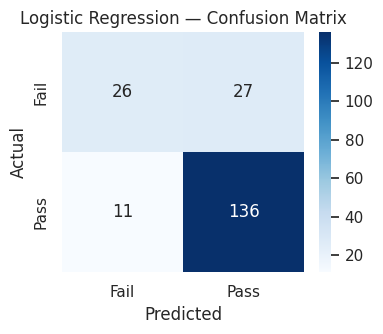

In [9]:
log_reg = LogisticRegression()
log_reg.fit(X_train_c_scaled, y_train_c)
y_pred_log = log_reg.predict(X_test_c_scaled)

print("Accuracy:", round(accuracy_score(y_test_c, y_pred_log), 3))
print(classification_report(y_test_c, y_pred_log, target_names=["Fail", "Pass"]))

cm = confusion_matrix(y_test_c, y_pred_log)
fig, ax = plt.subplots(figsize=(4, 3.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Fail", "Pass"], yticklabels=["Fail", "Pass"], ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()


### 3.2 K-Nearest Neighbors (KNN)

Accuracy: 0.735
              precision    recall  f1-score   support

        Fail       0.50      0.42      0.45        53
        Pass       0.80      0.85      0.83       147

    accuracy                           0.73       200
   macro avg       0.65      0.63      0.64       200
weighted avg       0.72      0.73      0.73       200



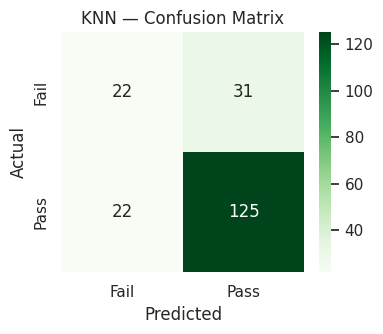

In [10]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_c_scaled, y_train_c)
y_pred_knn = knn.predict(X_test_c_scaled)

print("Accuracy:", round(accuracy_score(y_test_c, y_pred_knn), 3))
print(classification_report(y_test_c, y_pred_knn, target_names=["Fail", "Pass"]))

cm_knn = confusion_matrix(y_test_c, y_pred_knn)
fig, ax = plt.subplots(figsize=(4, 3.5))
sns.heatmap(cm_knn, annot=True, fmt="d", cmap="Greens",
            xticklabels=["Fail", "Pass"], yticklabels=["Fail", "Pass"], ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("KNN — Confusion Matrix")
plt.tight_layout()
plt.show()


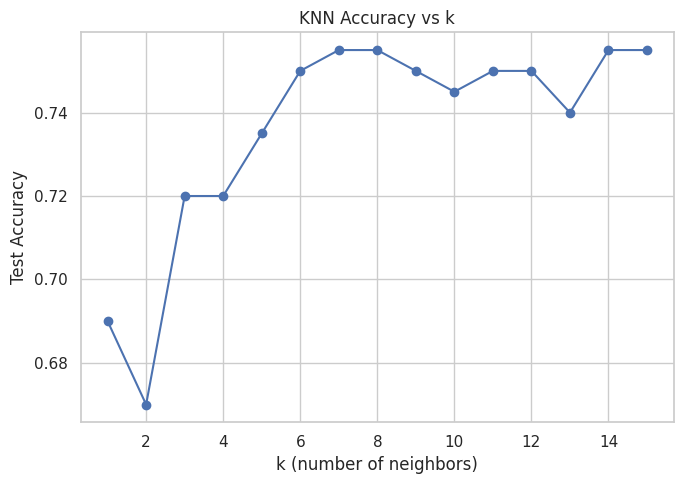

In [11]:
# Quick check: does k (number of neighbors) matter much here?
accuracies = []
k_values = range(1, 16)
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_c_scaled, y_train_c)
    acc = accuracy_score(y_test_c, model.predict(X_test_c_scaled))
    accuracies.append(acc)

fig, ax = plt.subplots()
ax.plot(list(k_values), accuracies, marker="o")
ax.set_xlabel("k (number of neighbors)")
ax.set_ylabel("Test Accuracy")
ax.set_title("KNN Accuracy vs k")
plt.tight_layout()
plt.show()


## 4. Summary

In [12]:
print("Regression results (R2 score):")
print(f"  Linear (1 feature)      : {r2_score(y_test, y_pred_lin):.3f}")
print(f"  Polynomial (1 feature)  : {r2_score(y_test, y_pred_poly):.3f}")
print(f"  Ridge (4 features)      : {r2_score(y_test_m, y_pred_ridge):.3f}")
print(f"  Lasso (4 features)      : {r2_score(y_test_m, y_pred_lasso):.3f}")
print()
print("Classification results (Accuracy):")
print(f"  Logistic Regression     : {accuracy_score(y_test_c, y_pred_log):.3f}")
print(f"  KNN (k=5)                : {accuracy_score(y_test_c, y_pred_knn):.3f}")
print(f"  Best k for KNN           : {list(k_values)[int(np.argmax(accuracies))]}")


Regression results (R2 score):
  Linear (1 feature)      : 0.286
  Polynomial (1 feature)  : 0.285
  Ridge (4 features)      : 0.428
  Lasso (4 features)      : 0.426

Classification results (Accuracy):
  Logistic Regression     : 0.810
  KNN (k=5)                : 0.735
  Best k for KNN           : 7
